# Introduction to Unsupervised Machine Learning
Unsupervised machine learning finds patterns in data without using predefined labels or target values. Instead of learning to predict a known answer, an algorithm explores the data’s structure.

## Common tasks

- **Clustering:** Groups similar observations, such as customer segments.
- **Dimensionality reduction:** Summarizes data using fewer features while retaining important structure.
- **Anomaly detection:** Identifies observations that differ substantially from the rest.

## Clustering with K-Means
K-Means divides data into a chosen number of clusters. It repeatedly assigns each observation to its nearest cluster center and updates the centers until the assignments stabilize.

In this notebook, `X` contains two-dimensional observations, `model` is a K-Means model configured for three clusters, and `cluster_ids` contains a cluster assignment for each observation. Cluster IDs are arbitrary labels; for example, cluster `0` is not inherently better or more meaningful than cluster `1`.

## Considerations
- Choose the number of clusters carefully; K-Means requires it in advance.
- Feature scales can affect distance-based clustering.
- Results may depend on initialization and the shape of the data.
- Clusters suggest structure, but interpreting them requires domain knowledge.

In [6]:
clustering_algorithms = [
    "K-Means",
    "Hierarchical clustering",
    "DBSCAN",
    "OPTICS",
    "Gaussian Mixture Models",
    "Spectral clustering",
    "Mean Shift",
    "Affinity Propagation",
]

Cluster centers:
[[-2.65882129  8.95756821]
 [-6.74539381 -6.85144337]
 [ 4.63218228  2.10121377]]

First 10 cluster assignments: [2 0 1 1 1 1 0 1 2 1]


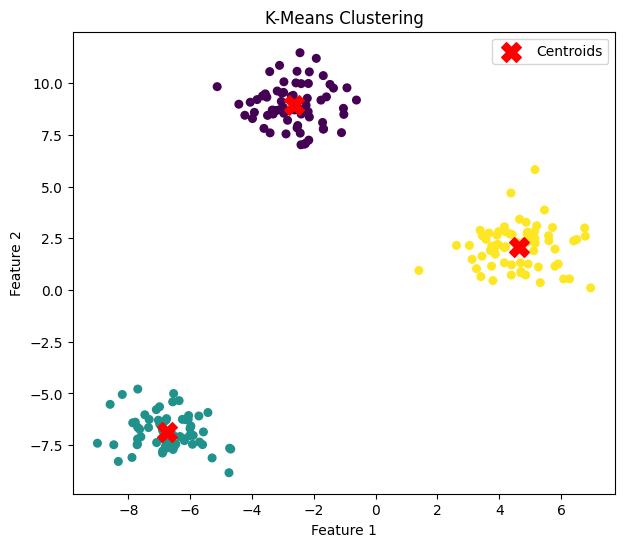

In [7]:
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

# Fit K-Means on the data
model = KMeans(n_clusters=3, random_state=42)
model.fit(X)

# Get cluster assignments and centroids
cluster_ids = model.labels_
centers = model.cluster_centers_

print("Cluster centers:")
print(centers)
print("\nFirst 10 cluster assignments:", cluster_ids[:10])

# Visualize the clusters
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=cluster_ids, cmap="viridis", s=30)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

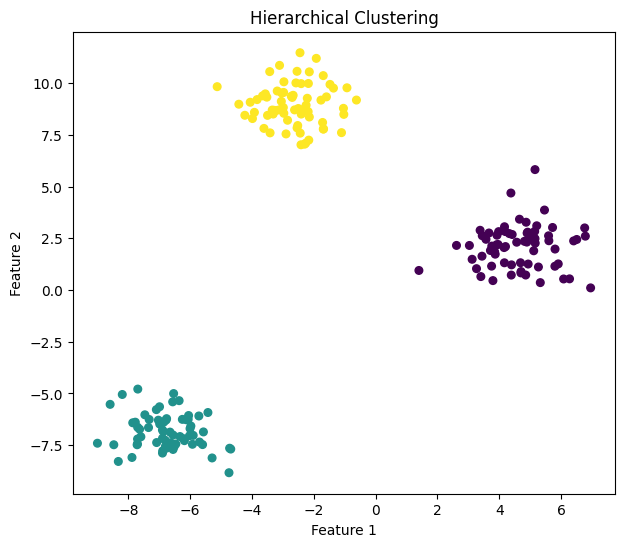

In [8]:
from sklearn.cluster import AgglomerativeClustering

# Fit hierarchical clustering and get cluster assignments
hierarchical_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
hierarchical_cluster_ids = hierarchical_model.fit_predict(X)

# Visualize the clusters
plt.figure(figsize=(7, 6))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

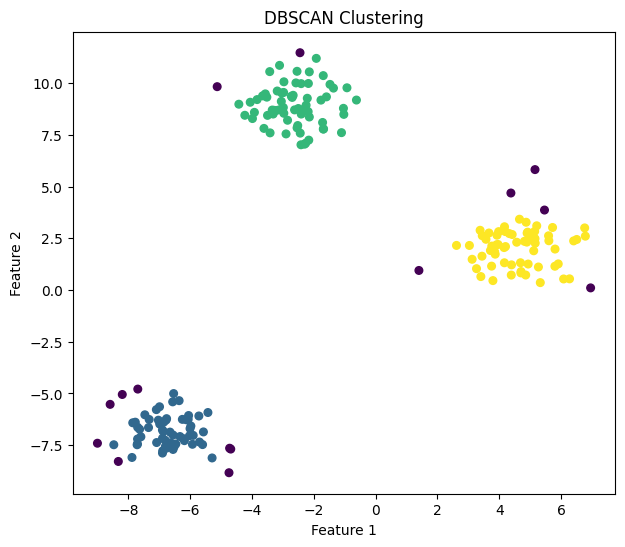

Cluster labels (including -1 for noise): {np.int64(0), np.int64(1), np.int64(2), np.int64(-1)}


In [9]:
from sklearn.cluster import DBSCAN

# Fit DBSCAN and get cluster assignments (-1 denotes noise)
dbscan_model = DBSCAN(eps=0.8, min_samples=5)
dbscan_cluster_ids = dbscan_model.fit_predict(X)

# Visualize the clusters
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=dbscan_cluster_ids, cmap="viridis", s=30)
plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Cluster labels (including -1 for noise):", set(dbscan_cluster_ids))

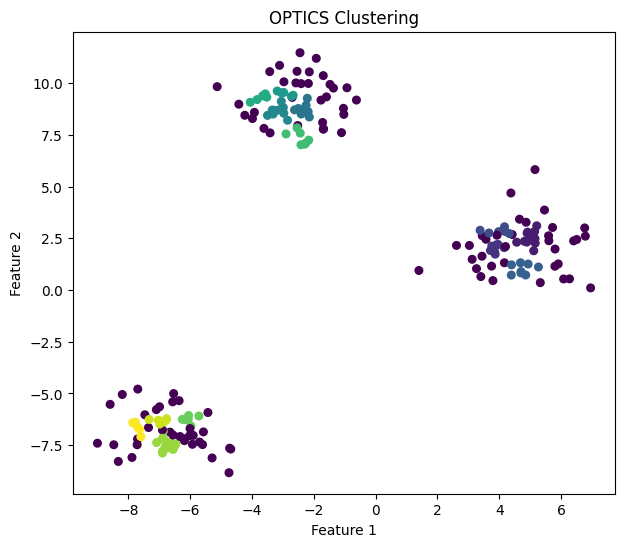

Cluster labels (including -1 for noise): {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(-1)}


In [10]:
from sklearn.cluster import OPTICS

# Fit OPTICS and get cluster assignments (-1 denotes noise)
optics_model = OPTICS(min_samples=5)
optics_cluster_ids = optics_model.fit_predict(X)

# Visualize the clusters
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=optics_cluster_ids, cmap="viridis", s=30)
plt.title("OPTICS Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Cluster labels (including -1 for noise):", set(optics_cluster_ids))

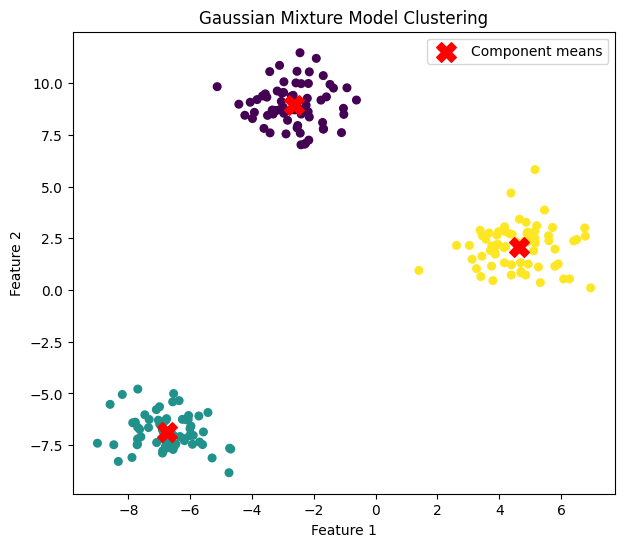

In [11]:
from sklearn.mixture import GaussianMixture

# Fit a Gaussian Mixture Model and assign clusters
gmm_model = GaussianMixture(n_components=3, random_state=42)
gmm_cluster_ids = gmm_model.fit_predict(X)

# Visualize the clusters and component means
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=gmm_cluster_ids, cmap="viridis", s=30)
plt.scatter(
    gmm_model.means_[:, 0],
    gmm_model.means_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Component means",
)
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


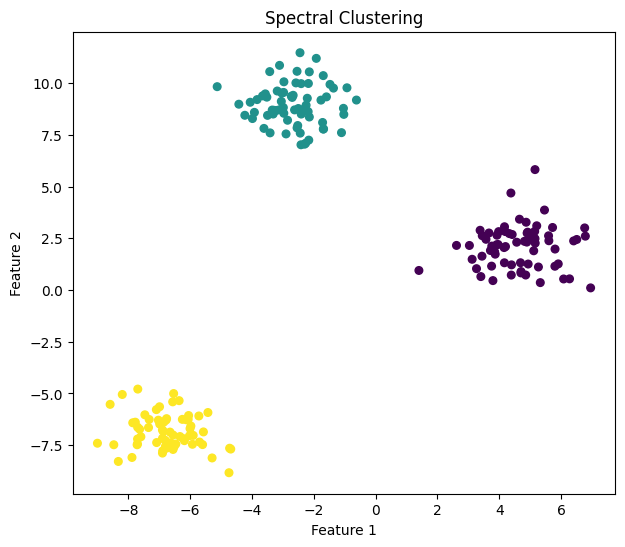

In [12]:
from sklearn.cluster import SpectralClustering

# Fit spectral clustering and get cluster assignments
spectral_model = SpectralClustering(
    n_clusters=3,
    affinity="nearest_neighbors",
    n_neighbors=10,
    random_state=42,
)
spectral_cluster_ids = spectral_model.fit_predict(X)

# Visualize the clusters
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=spectral_cluster_ids, cmap="viridis", s=30)
plt.title("Spectral Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

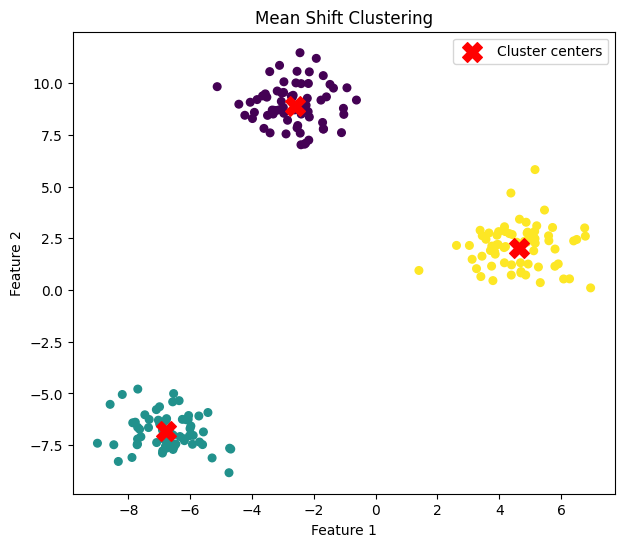

Number of clusters found: 3


In [13]:
from sklearn.cluster import MeanShift

# Fit Mean Shift and get cluster assignments
meanshift_model = MeanShift(bandwidth=2.5)
meanshift_cluster_ids = meanshift_model.fit_predict(X)
meanshift_centers = meanshift_model.cluster_centers_

# Visualize the clusters and their centers
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=meanshift_cluster_ids, cmap="viridis", s=30)
plt.scatter(
    meanshift_centers[:, 0],
    meanshift_centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Cluster centers",
)
plt.title("Mean Shift Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

print(f"Number of clusters found: {len(meanshift_centers)}")

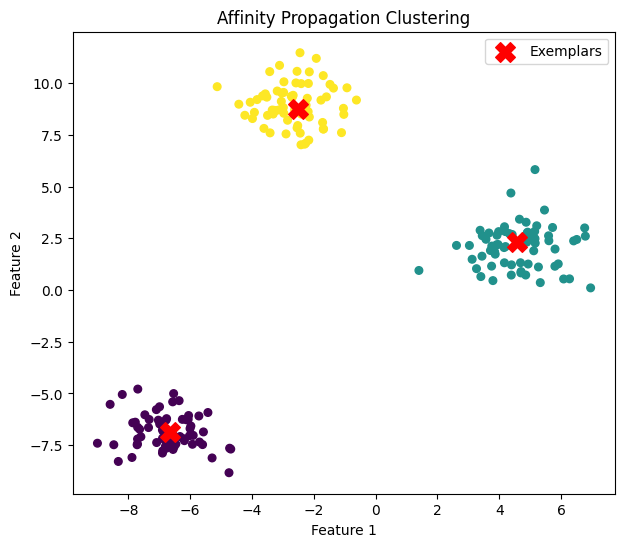

Number of clusters found: 3


In [14]:
from sklearn.cluster import AffinityPropagation

# Fit Affinity Propagation and get cluster assignments
affinity_model = AffinityPropagation(random_state=42)
affinity_cluster_ids = affinity_model.fit_predict(X)

# Get exemplar points (cluster centers)
center_indices = affinity_model.cluster_centers_indices_
affinity_centers = X[center_indices]

# Visualize clusters and exemplars
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=affinity_cluster_ids, cmap="viridis", s=30)
plt.scatter(
    affinity_centers[:, 0],
    affinity_centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Exemplars",
)
plt.title("Affinity Propagation Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

print(f"Number of clusters found: {len(affinity_centers)}")

In [15]:
dimensionality_reduction_algorithms = [
    ("PCA", "Linear projection that preserves as much variance as possible."),
    ("Truncated SVD", "PCA-like reduction, often used with sparse data."),
    ("Kernel PCA", "Nonlinear extension of PCA using kernel functions."),
    ("t-SNE", "Nonlinear method commonly used to visualize high-dimensional data."),
    ("UMAP", "Nonlinear method for visualization and general-purpose reduction."),
    ("Isomap", "Preserves distances along the data manifold."),
    ("Locally Linear Embedding (LLE)", "Preserves local neighborhood relationships."),
    ("Multidimensional Scaling (MDS)", "Maps data to preserve pairwise distances."),
    ("Autoencoders", "Neural networks trained to encode and reconstruct data."),
    ("Linear Discriminant Analysis (LDA)", "Supervised reduction that separates known classes."),
]

for name, description in dimensionality_reduction_algorithms:
    print(f"{name}: {description}")

PCA: Linear projection that preserves as much variance as possible.
Truncated SVD: PCA-like reduction, often used with sparse data.
Kernel PCA: Nonlinear extension of PCA using kernel functions.
t-SNE: Nonlinear method commonly used to visualize high-dimensional data.
UMAP: Nonlinear method for visualization and general-purpose reduction.
Isomap: Preserves distances along the data manifold.
Locally Linear Embedding (LLE): Preserves local neighborhood relationships.
Multidimensional Scaling (MDS): Maps data to preserve pairwise distances.
Autoencoders: Neural networks trained to encode and reconstruct data.
Linear Discriminant Analysis (LDA): Supervised reduction that separates known classes.


Explained variance ratio: [0.74508146 0.25491854]
Total variance retained: 100.00%


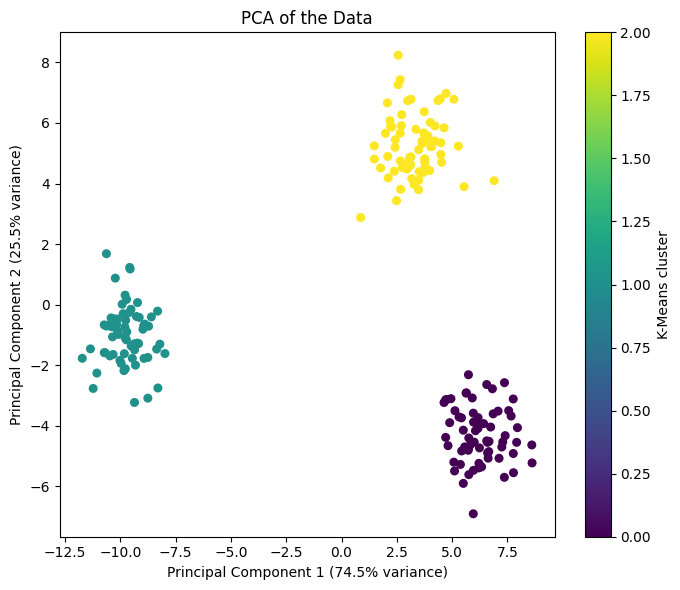

In [17]:
from sklearn.decomposition import PCA

# Fit PCA and transform X into principal-component coordinates
pca_model = PCA(n_components=2)
X_pca = pca_model.fit_transform(X)

print("Explained variance ratio:", pca_model.explained_variance_ratio_)
print(f"Total variance retained: {pca_model.explained_variance_ratio_.sum():.2%}")

# Visualize the PCA-transformed observations, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("PCA of the Data")
plt.xlabel(f"Principal Component 1 ({pca_model.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"Principal Component 2 ({pca_model.explained_variance_ratio_[1]:.1%} variance)")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

Explained variance ratio: [0.74416219 0.25583781]
Total variance retained: 100.00%


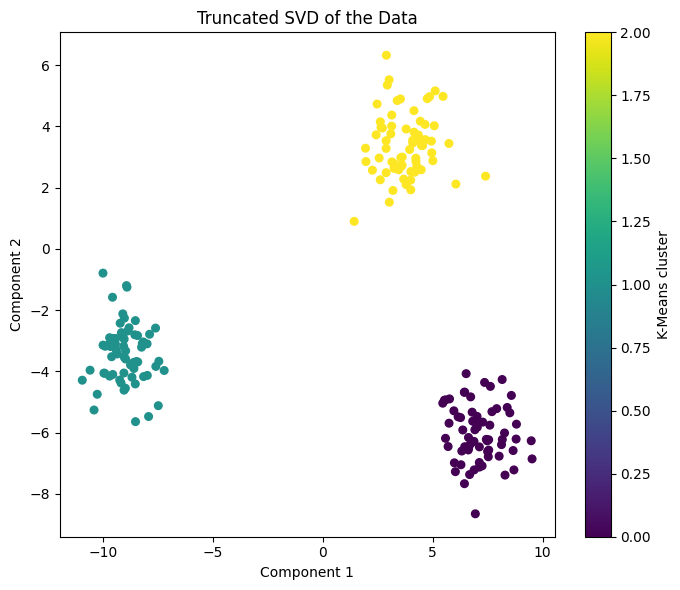

In [18]:
from sklearn.decomposition import TruncatedSVD

# Reduce X to two dimensions
svd_model = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd_model.fit_transform(X)

print("Explained variance ratio:", svd_model.explained_variance_ratio_)
print(f"Total variance retained: {svd_model.explained_variance_ratio_.sum():.2%}")

# Visualize the reduced data, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_svd[:, 0], X_svd[:, 1], c=cluster_ids, cmap="viridis", s=30)
plt.title("Truncated SVD of the Data")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

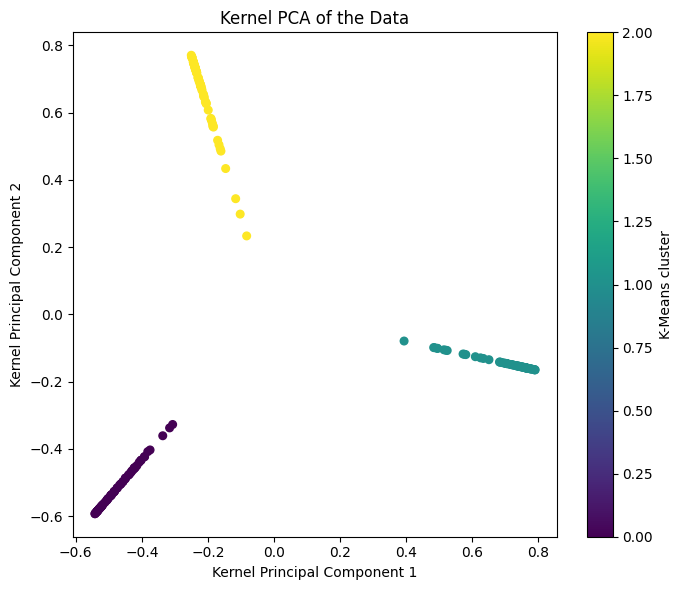

In [19]:
from sklearn.decomposition import KernelPCA

# Fit Kernel PCA and transform X into two nonlinear components
kpca_model = KernelPCA(n_components=2, kernel="rbf", gamma=0.1)
X_kpca = kpca_model.fit_transform(X)

# Visualize the transformed observations, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_kpca[:, 0],
    X_kpca[:, 1],
    c=cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("Kernel PCA of the Data")
plt.xlabel("Kernel Principal Component 1")
plt.ylabel("Kernel Principal Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

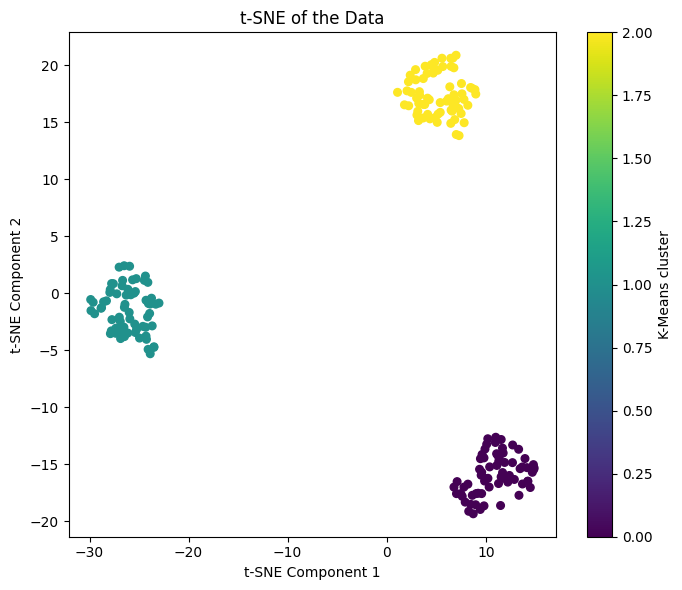

In [20]:
from sklearn.manifold import TSNE

# Fit t-SNE and reduce X to two dimensions
tsne_model = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42,
)
X_tsne = tsne_model.fit_transform(X)

# Visualize the transformed observations, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_ids, cmap="viridis", s=30)
plt.title("t-SNE of the Data")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 3 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Chan

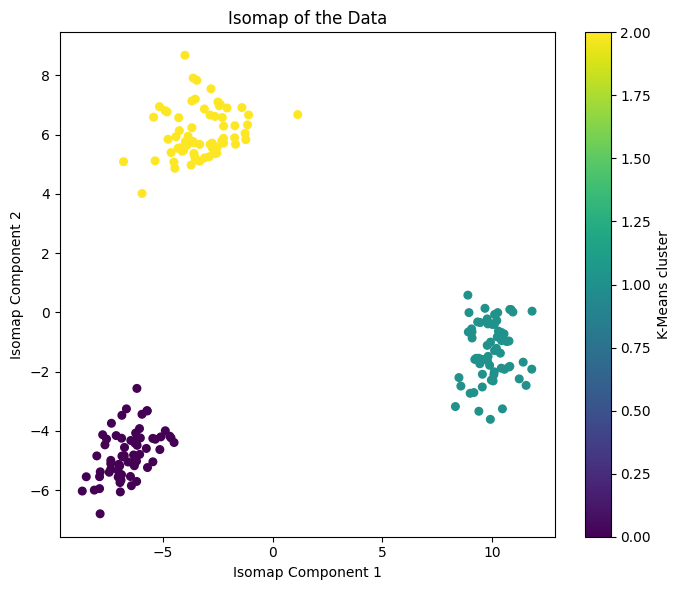

In [22]:
from sklearn.manifold import Isomap

# Fit Isomap to embed X in two dimensions while preserving geodesic distances
isomap_model = Isomap(n_neighbors=10, n_components=2)
X_isomap = isomap_model.fit_transform(X)

# Visualize the manifold embedding, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_isomap[:, 0],
    X_isomap[:, 1],
    c=cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("Isomap of the Data")
plt.xlabel("Isomap Component 1")
plt.ylabel("Isomap Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

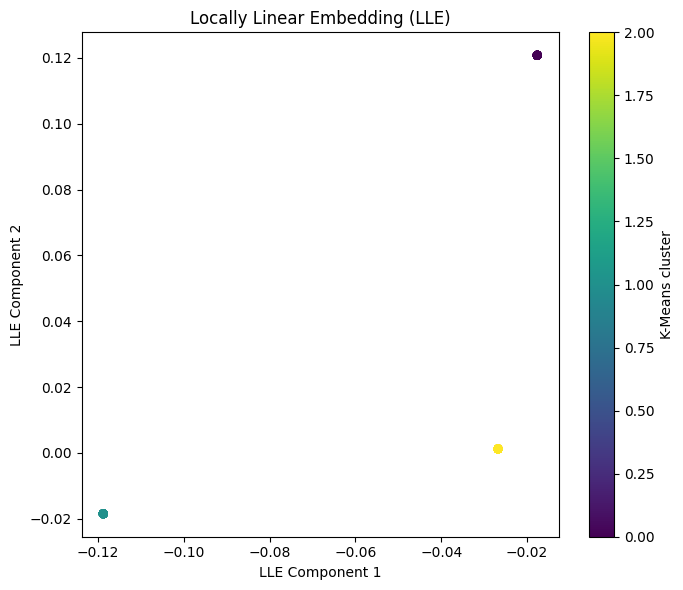

In [23]:
from sklearn.manifold import LocallyLinearEmbedding

# Embed X in two dimensions while preserving local neighborhood relationships
lle_model = LocallyLinearEmbedding(
    n_neighbors=10,
    n_components=2,
    random_state=42,
)
X_lle = lle_model.fit_transform(X)

# Visualize the embedding, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_lle[:, 0],
    X_lle[:, 1],
    c=cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("Locally Linear Embedding (LLE)")
plt.xlabel("LLE Component 1")
plt.ylabel("LLE Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

c:\Users\Warka Academy\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


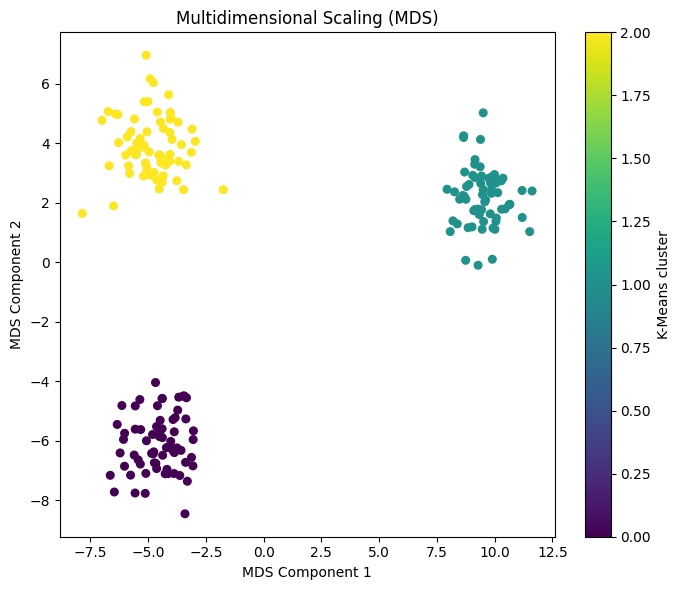

In [24]:
from sklearn.manifold import MDS

# Embed X in two dimensions while approximately preserving pairwise distances
mds_model = MDS(n_components=2, random_state=42)
X_mds = mds_model.fit_transform(X)

# Visualize the embedding, colored by K-Means assignment
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_mds[:, 0],
    X_mds[:, 1],
    c=cluster_ids,
    cmap="viridis",
    s=30,
)
plt.title("Multidimensional Scaling (MDS)")
plt.xlabel("MDS Component 1")
plt.ylabel("MDS Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.show()

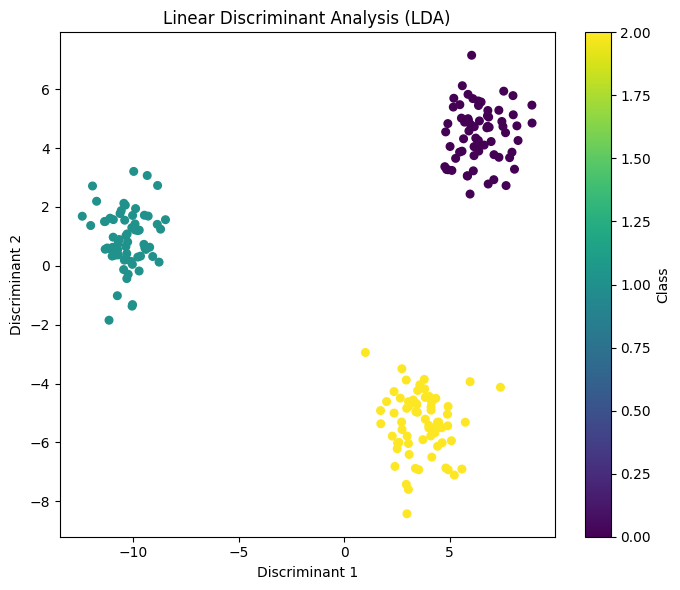

In [26]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# K-Means assignments are demonstration labels, not ground truth
y = cluster_ids
n_components = min(2, X.shape[1], len(set(y)) - 1)

lda_model = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda_model.fit_transform(X, y)

plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    X_lda[:, 0],
    X_lda[:, 1] if X_lda.shape[1] > 1 else [0] * len(X_lda),
    c=y,
    cmap="viridis",
    s=30,
)
plt.title("Linear Discriminant Analysis (LDA)")
plt.xlabel("Discriminant 1")
plt.ylabel("Discriminant 2" if X_lda.shape[1] > 1 else "")
plt.colorbar(scatter, label="Class")
plt.tight_layout()
plt.show()

In [16]:
anomaly_detection_algorithms = [
    ("Isolation Forest", "Isolates observations using random feature splits; effective for high-dimensional data."),
    ("Local Outlier Factor (LOF)", "Flags observations with substantially lower local density than their neighbors."),
    ("One-Class SVM", "Learns a boundary around typical observations and identifies points outside it."),
    ("Elliptic Envelope", "Uses a robust covariance estimate to detect points far from an assumed Gaussian distribution."),
    ("DBSCAN", "Treats observations outside dense regions as noise; useful when clusters have irregular shapes."),
    ("k-Nearest Neighbors (k-NN)", "Detects anomalies using their distance from nearby observations."),
    ("Histogram-Based Outlier Score (HBOS)", "Scores observations using feature-wise histogram densities."),
    ("Autoencoders", "Flags observations that a neural network reconstructs poorly."),
    ("PCA Reconstruction Error", "Flags observations poorly represented by a lower-dimensional projection."),
    ("Statistical methods (e.g., Z-score)", "Identifies values that depart from expected statistical ranges."),
]

for name, description in anomaly_detection_algorithms:
    print(f"{name}: {description}")

Isolation Forest: Isolates observations using random feature splits; effective for high-dimensional data.
Local Outlier Factor (LOF): Flags observations with substantially lower local density than their neighbors.
One-Class SVM: Learns a boundary around typical observations and identifies points outside it.
Elliptic Envelope: Uses a robust covariance estimate to detect points far from an assumed Gaussian distribution.
DBSCAN: Treats observations outside dense regions as noise; useful when clusters have irregular shapes.
k-Nearest Neighbors (k-NN): Detects anomalies using their distance from nearby observations.
Histogram-Based Outlier Score (HBOS): Scores observations using feature-wise histogram densities.
Autoencoders: Flags observations that a neural network reconstructs poorly.
PCA Reconstruction Error: Flags observations poorly represented by a lower-dimensional projection.
Statistical methods (e.g., Z-score): Identifies values that depart from expected statistical ranges.


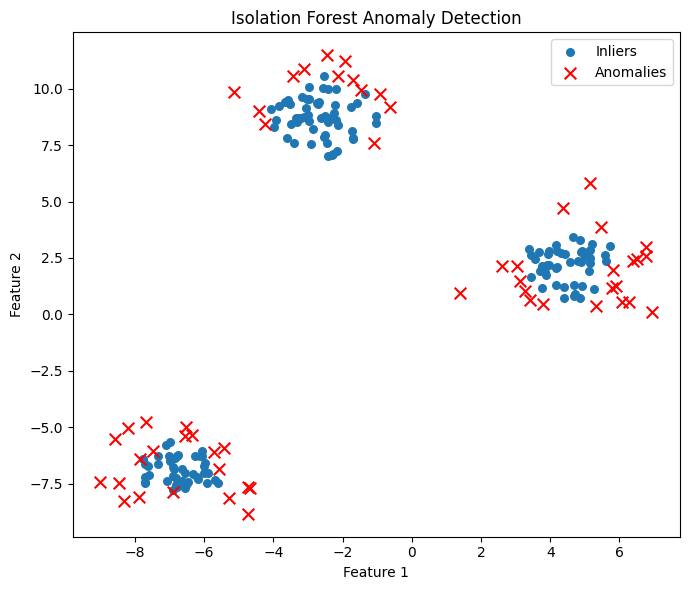

Anomalies detected: 54 of 200 observations


In [27]:
from sklearn.ensemble import IsolationForest

# Fit Isolation Forest; -1 marks anomalies and 1 marks inliers
isolation_model = IsolationForest(contamination="auto", random_state=42)
anomaly_labels = isolation_model.fit_predict(X)
anomaly_mask = anomaly_labels == -1

# Visualize observations and detected anomalies
plt.figure(figsize=(7, 6))
plt.scatter(X[~anomaly_mask, 0], X[~anomaly_mask, 1], label="Inliers", s=30)
plt.scatter(
    X[anomaly_mask, 0],
    X[anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("Isolation Forest Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Anomalies detected: {anomaly_mask.sum()} of {len(X)} observations")

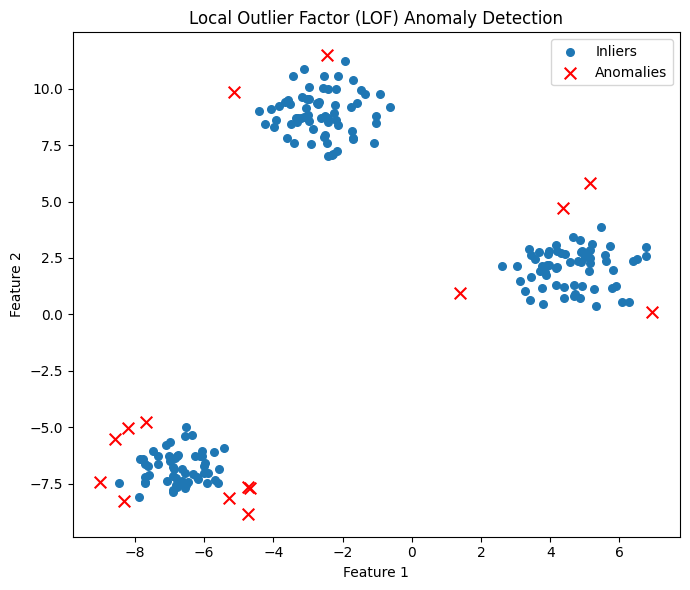

Anomalies detected: 15 of 200 observations


In [28]:
from sklearn.neighbors import LocalOutlierFactor

# Fit LOF; -1 marks anomalies and 1 marks inliers
lof_model = LocalOutlierFactor(n_neighbors=20, contamination="auto")
lof_labels = lof_model.fit_predict(X)
lof_anomaly_mask = lof_labels == -1

# Visualize observations and detected anomalies
plt.figure(figsize=(7, 6))
plt.scatter(
    X[~lof_anomaly_mask, 0],
    X[~lof_anomaly_mask, 1],
    label="Inliers",
    s=30,
)
plt.scatter(
    X[lof_anomaly_mask, 0],
    X[lof_anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("Local Outlier Factor (LOF) Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Anomalies detected: {lof_anomaly_mask.sum()} of {len(X)} observations")

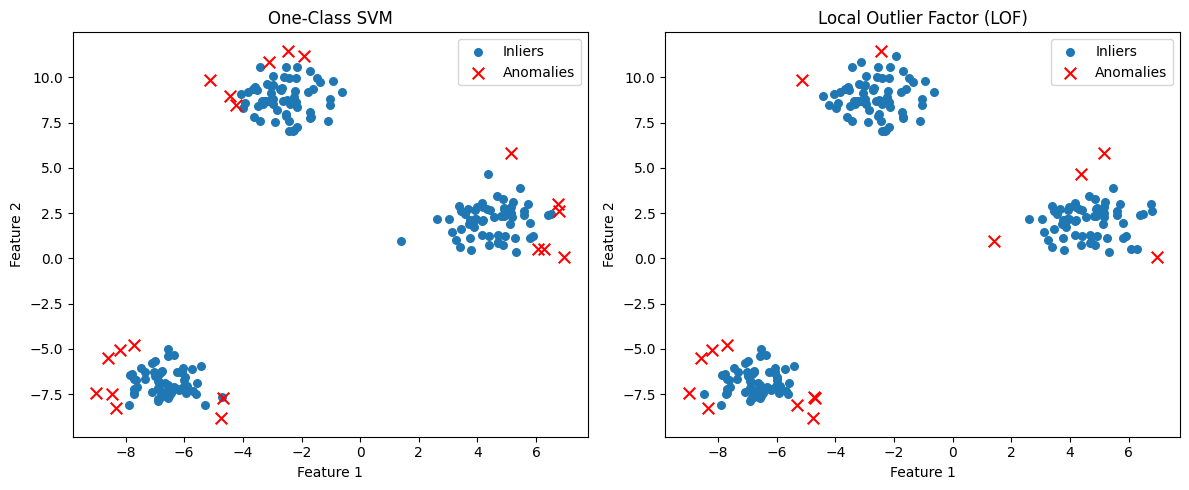

One-Class SVM anomalies: 20 of 200
LOF anomalies: 15 of 200


In [29]:
from sklearn.svm import OneClassSVM

# Fit One-Class SVM; -1 marks anomalies and 1 marks inliers
svm_model = OneClassSVM(kernel="rbf", gamma="scale", nu=0.1)
svm_labels = svm_model.fit_predict(X)
svm_anomaly_mask = svm_labels == -1

# Compare detected anomalies
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, mask, title in [
    (axes[0], svm_anomaly_mask, "One-Class SVM"),
    (axes[1], lof_anomaly_mask, "Local Outlier Factor (LOF)"),
]:
    ax.scatter(X[~mask, 0], X[~mask, 1], label="Inliers", s=30)
    ax.scatter(
        X[mask, 0], X[mask, 1],
        color="red", marker="x", label="Anomalies", s=70,
    )
    ax.set(title=title, xlabel="Feature 1", ylabel="Feature 2")
    ax.legend()

plt.tight_layout()
plt.show()

print(f"One-Class SVM anomalies: {svm_anomaly_mask.sum()} of {len(X)}")
print(f"LOF anomalies: {lof_anomaly_mask.sum()} of {len(X)}")

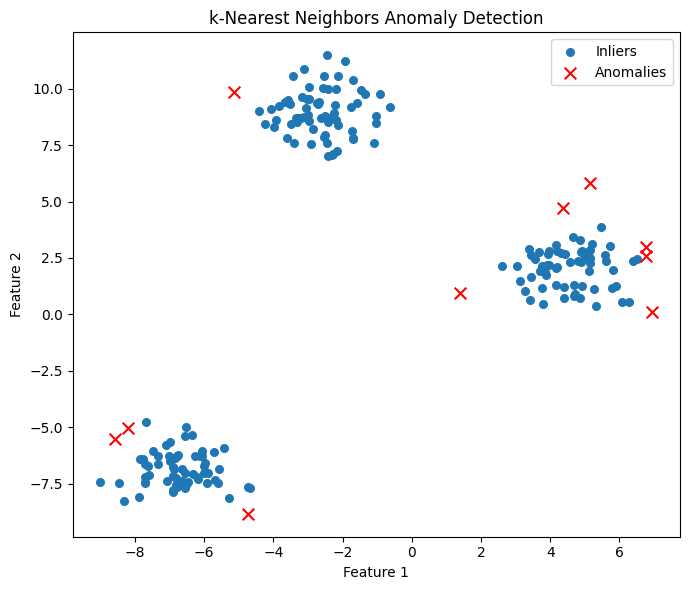

Anomalies detected: 10 of 200 observations


In [30]:
from sklearn.neighbors import NearestNeighbors

knn_k = 10
knn_neighbors = NearestNeighbors(n_neighbors=knn_k + 1)
knn_distances, _ = knn_neighbors.fit(X).kneighbors(X)

# The first neighbor is the observation itself; use the kth other neighbor.
knn_scores = knn_distances[:, -1]
knn_threshold = np.percentile(knn_scores, 95)
knn_anomaly_mask = knn_scores > knn_threshold

plt.figure(figsize=(7, 6))
plt.scatter(
    X[~knn_anomaly_mask, 0],
    X[~knn_anomaly_mask, 1],
    label="Inliers",
    s=30,
)
plt.scatter(
    X[knn_anomaly_mask, 0],
    X[knn_anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("k-Nearest Neighbors Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Anomalies detected: {knn_anomaly_mask.sum()} of {len(X)} observations")

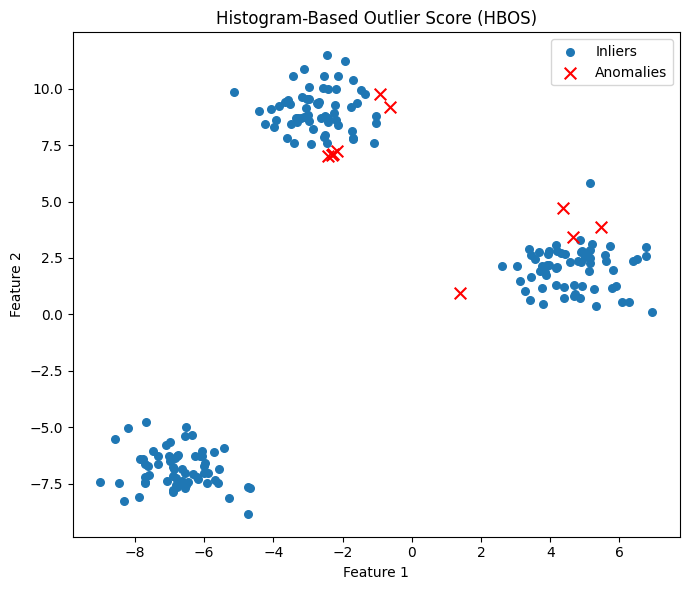

Anomalies detected: 10 of 200 observations


In [31]:
# Compute HBOS scores using independent histograms for each feature
hbos_bins = 10
hbos_scores = np.zeros(len(X))

for feature_idx in range(X.shape[1]):
    counts, bin_edges = np.histogram(X[:, feature_idx], bins=hbos_bins)
    bin_indices = np.clip(
        np.searchsorted(bin_edges[1:-1], X[:, feature_idx]),
        0,
        len(counts) - 1,
    )

    # Estimate density in each bin and add its negative log-density
    bin_widths = np.diff(bin_edges)
    densities = counts / (len(X) * bin_widths)
    hbos_scores += -np.log(np.maximum(densities[bin_indices], 1e-12))

hbos_threshold = np.percentile(hbos_scores, 95)
hbos_anomaly_mask = hbos_scores >= hbos_threshold

# Visualize observations and detected anomalies
plt.figure(figsize=(7, 6))
plt.scatter(
    X[~hbos_anomaly_mask, 0],
    X[~hbos_anomaly_mask, 1],
    label="Inliers",
    s=30,
)
plt.scatter(
    X[hbos_anomaly_mask, 0],
    X[hbos_anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("Histogram-Based Outlier Score (HBOS)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Anomalies detected: {hbos_anomaly_mask.sum()} of {len(X)} observations")

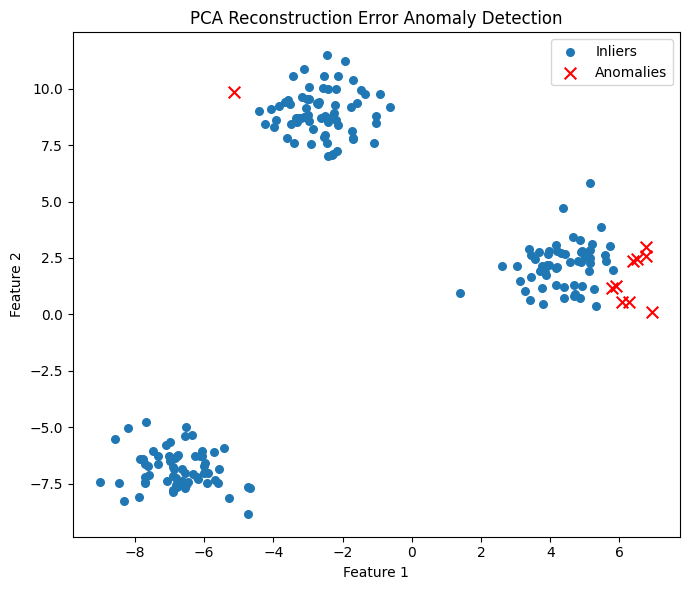

Anomalies detected: 10 of 200 observations


In [32]:
# Reconstruct X using one principal component
reconstruction_pca_model = PCA(n_components=1)
X_reduced = reconstruction_pca_model.fit_transform(X)
X_reconstructed = reconstruction_pca_model.inverse_transform(X_reduced)

# Score each observation by its squared reconstruction error
reconstruction_errors = np.sum((X - X_reconstructed) ** 2, axis=1)
reconstruction_threshold = np.percentile(reconstruction_errors, 95)
reconstruction_anomaly_mask = reconstruction_errors > reconstruction_threshold

# Visualize observations and detected anomalies
plt.figure(figsize=(7, 6))
plt.scatter(
    X[~reconstruction_anomaly_mask, 0],
    X[~reconstruction_anomaly_mask, 1],
    label="Inliers",
    s=30,
)
plt.scatter(
    X[reconstruction_anomaly_mask, 0],
    X[reconstruction_anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("PCA Reconstruction Error Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Anomalies detected: {reconstruction_anomaly_mask.sum()} "
    f"of {len(X)} observations"
)

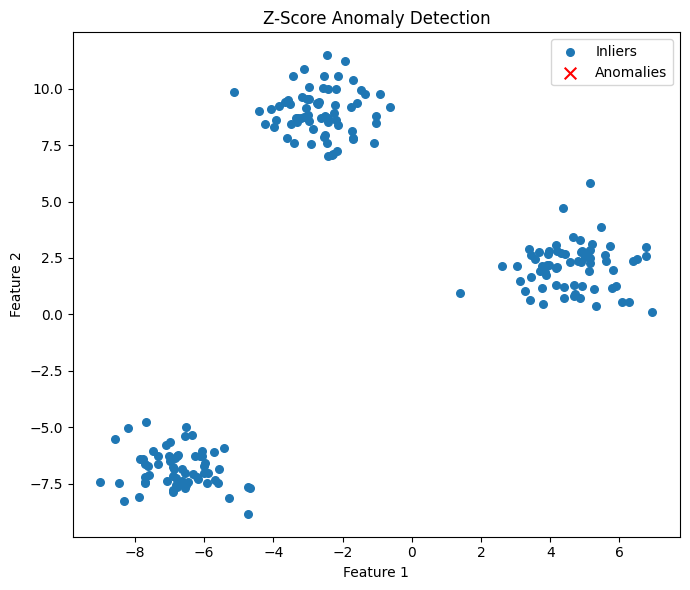

Anomalies detected: 0 of 200 observations


In [33]:
# Detect observations with a Z-score above 3 in any feature
feature_std = X.std(axis=0)
feature_std[feature_std == 0] = 1  # Avoid division by zero for constant features
z_scores = (X - X.mean(axis=0)) / feature_std
zscore_anomaly_mask = (abs(z_scores) > 3).any(axis=1)

# Visualize inliers and detected anomalies
plt.figure(figsize=(7, 6))
plt.scatter(
    X[~zscore_anomaly_mask, 0],
    X[~zscore_anomaly_mask, 1],
    label="Inliers",
    s=30,
)
plt.scatter(
    X[zscore_anomaly_mask, 0],
    X[zscore_anomaly_mask, 1],
    color="red",
    marker="x",
    label="Anomalies",
    s=70,
)
plt.title("Z-Score Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Anomalies detected: {zscore_anomaly_mask.sum()} of {len(X)} observations")

In [34]:
anomaly_masks = {
    "Isolation Forest": anomaly_mask,
    "LOF": lof_anomaly_mask,
    "One-Class SVM": svm_anomaly_mask,
    "k-NN": knn_anomaly_mask,
    "HBOS": hbos_anomaly_mask,
    "PCA reconstruction error": reconstruction_anomaly_mask,
    "Z-score": zscore_anomaly_mask,
}

print("Anomalies detected:")
for name, mask in anomaly_masks.items():
    print(f"{name}: {mask.sum()} of {len(mask)} ({mask.mean():.1%})")

print("\nPairwise Jaccard overlap:")
names = list(anomaly_masks)
for i, name_a in enumerate(names):
    for name_b in names[i + 1:]:
        a, b = anomaly_masks[name_a], anomaly_masks[name_b]
        union = (a | b).sum()
        overlap = (a & b).sum() / union if union else 1.0
        print(f"{name_a} vs {name_b}: {overlap:.2f}")

Anomalies detected:
Isolation Forest: 54 of 200 (27.0%)
LOF: 15 of 200 (7.5%)
One-Class SVM: 20 of 200 (10.0%)
k-NN: 10 of 200 (5.0%)
HBOS: 10 of 200 (5.0%)
PCA reconstruction error: 10 of 200 (5.0%)
Z-score: 0 of 200 (0.0%)

Pairwise Jaccard overlap:
Isolation Forest vs LOF: 0.28
Isolation Forest vs One-Class SVM: 0.37
Isolation Forest vs k-NN: 0.19
Isolation Forest vs HBOS: 0.08
Isolation Forest vs PCA reconstruction error: 0.19
Isolation Forest vs Z-score: 0.00
LOF vs One-Class SVM: 0.46
LOF vs k-NN: 0.47
LOF vs HBOS: 0.09
LOF vs PCA reconstruction error: 0.09
LOF vs Z-score: 0.00
One-Class SVM vs k-NN: 0.36
One-Class SVM vs HBOS: 0.00
One-Class SVM vs PCA reconstruction error: 0.25
One-Class SVM vs Z-score: 0.00
k-NN vs HBOS: 0.11
k-NN vs PCA reconstruction error: 0.25
k-NN vs Z-score: 0.00
HBOS vs PCA reconstruction error: 0.00
HBOS vs Z-score: 0.00
PCA reconstruction error vs Z-score: 0.00
